In [1]:
import sys
sys.path.insert(0, "../src")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import seaborn as sns

from cwfc.data     import load_raw, build_targets
from cwfc.features import (
    build_category_ts, build_fleet_ts, build_features,
    split_features, CATEGORIES
)

sns.set_theme(style="darkgrid", font_scale=1.05)
DATA_DIR  = Path("../challenge_data")
TRAIN_OBS = 110
RNG       = 42

meta, cpu = load_raw(DATA_DIR)
targets   = build_targets(cpu)
cat_ts    = build_category_ts(cpu, meta)
fleet_ts  = build_fleet_ts(cpu, meta)
feat_df   = build_features(targets, cat_ts, meta, fleet_ts=fleet_ts)

X_train, X_test, y_train, y_test = split_features(feat_df, TRAIN_OBS)
test_timestamps = targets.iloc[TRAIN_OBS:]["timestamp"].values

print(f"X_train {X_train.shape}  X_test {X_test.shape}")
print(f"Features ({len(X_train.columns)}): {X_train.columns.tolist()}")
print(f"y_train mean={y_train.mean():.3f}  y_test mean={y_test.mean():.3f}")


X_train (104, 10)  X_test (24, 10)
Features (10): ['aggregate_cpu_utilization_lag1', 'aggregate_cpu_utilization_lag2', 'aggregate_cpu_utilization_lag3', 'aggregate_cpu_utilization_diff1', 'aggregate_cpu_utilization_roll3_mean', 'aggregate_cpu_utilization_roll6_mean', 'cpu_Delay-insensitive_lag1', 'cpu_Interactive_lag1', 'cpu_Unknown_lag1', 'core_weighted_cpu_lag1']
y_train mean=9.417  y_test mean=9.269


## 1. Baselines

In [2]:
def mae(y_true, y_pred):  return np.mean(np.abs(y_true - y_pred))
def rmse(y_true, y_pred): return np.sqrt(np.mean((y_true - y_pred) ** 2))
def nmae(y_true, y_pred, baseline_mae): return mae(y_true, y_pred) / baseline_mae

train_series = targets.iloc[:TRAIN_OBS]["aggregate_cpu_utilization"].values
test_series  = y_test.values
TEST_OBS     = len(test_series)

# Baseline 1: Persistence (last observed value in training)
pred_persist = np.full(TEST_OBS, train_series[-1])

# Baseline 2: 60-minute Moving Average
pred_ma = np.full(TEST_OBS, train_series[-12:].mean())

results = {
    "Persistence"     : (pred_persist, mae(test_series, pred_persist), rmse(test_series, pred_persist)),
    "Moving avg (60m)": (pred_ma,      mae(test_series, pred_ma),      rmse(test_series, pred_ma)),
}

baseline_mae = results["Persistence"][1]
print(f"Persistence baseline MAE: {baseline_mae:.4f}  RMSE: {results['Persistence'][2]:.4f}")
print(f"Moving avg baseline  MAE: {results['Moving avg (60m)'][1]:.4f}  RMSE: {results['Moving avg (60m)'][2]:.4f}")


Persistence baseline MAE: 0.1468  RMSE: 0.1848
Moving avg baseline  MAE: 0.1230  RMSE: 0.1613


## 2. LightGBM — aggregate target

In [3]:
LGBM_PARAMS = dict(
    objective="regression_l1",   # MAE loss
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=8,
    min_child_samples=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    random_state=RNG,
    verbose=-1,
)

# Time-aware validation: expanding-window CV on training data
FOLD_ORIGINS = [54, 79]   # last training index of each fold

X_all = X_train.reset_index(drop=True)
y_all = y_train.reset_index(drop=True)

cv_scores = []
for origin in FOLD_ORIGINS:
    Xtr, Xval = X_all.iloc[:origin+1], X_all.iloc[origin+1:origin+25]
    ytr, yval = y_all.iloc[:origin+1], y_all.iloc[origin+1:origin+25]
    m = lgb.LGBMRegressor(**LGBM_PARAMS)
    m.fit(Xtr, ytr)
    pval = m.predict(Xval)
    cv_scores.append(mae(yval.values, pval))
    print(f"  Fold origin={origin}: val MAE={cv_scores[-1]:.4f}")

print(f"Mean CV MAE: {np.mean(cv_scores):.4f}")


  Fold origin=54: val MAE=0.1317
  Fold origin=79: val MAE=0.1528
Mean CV MAE: 0.1422


In [4]:
# Final model trained on all 86 clean training rows
lgbm_agg = lgb.LGBMRegressor(**LGBM_PARAMS)
lgbm_agg.fit(X_train, y_train)
pred_lgbm_agg = lgbm_agg.predict(X_test)

m_agg  = mae(test_series,  pred_lgbm_agg)
r_agg  = rmse(test_series, pred_lgbm_agg)
nm_agg = nmae(test_series, pred_lgbm_agg, baseline_mae)

print(f"LightGBM (agg)  MAE={m_agg:.4f}  RMSE={r_agg:.4f}  nMAE={nm_agg:.4f}")

LightGBM (agg)  MAE=0.1033  RMSE=0.1380  nMAE=0.7039


## 3. Results comparison


In [5]:
all_results = {
    **{k: (v[0], v[1], v[2]) for k, v in results.items()},
    "LightGBM (Best Model)" : (pred_lgbm_agg, m_agg,  r_agg),
}

print(f"{'Model':<24} {'MAE':>8} {'RMSE':>8} {'nMAE':>8} {'vs baseline':>12}")
print("-" * 64)
for name, (_, m, r) in all_results.items():
    nm = m / baseline_mae
    impr = (1 - nm) * 100
    flag = " <-- BEST" if name == "LightGBM (Best Model)" else ""
    print(f"{name:<24} {m:8.4f} {r:8.4f} {nm:8.4f} {impr:>10.1f}%{flag}")

final_pred = pred_lgbm_agg
final_name = "LightGBM"
final_mae, final_rmse, final_nmae = m_agg, r_agg, nm_agg

print(f"\nSelected best model: {final_name}")
target_met = "YES" if final_nmae < 0.8 else "NO"
print(f"nMAE < 0.80 target met: {target_met}  (nMAE = {final_nmae:.4f})")


Model                         MAE     RMSE     nMAE  vs baseline
----------------------------------------------------------------
Persistence                0.1468   0.1848   1.0000        0.0%
Moving avg (60m)           0.1230   0.1613   0.8380       16.2%
LightGBM (Best Model)      0.1033   0.1380   0.7039       29.6% <-- BEST

Selected best model: LightGBM
nMAE < 0.80 target met: YES  (nMAE = 0.7039)


## 4. Forecast visualisation


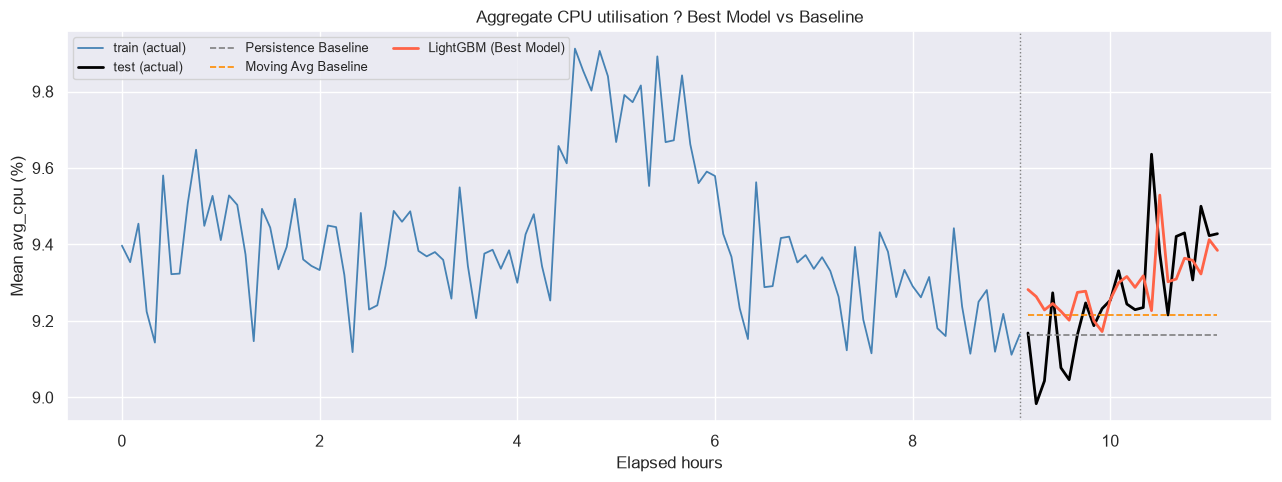

In [6]:
test_hours = test_timestamps / 3600
train_hours = targets.iloc[:TRAIN_OBS]["timestamp"].values / 3600

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_hours, train_series, color="steelblue", label="train (actual)", lw=1.3)
ax.plot(test_hours,  test_series,  color="black",     label="test (actual)",  lw=2)
ax.plot(test_hours,  pred_persist, color="gray",      label="Persistence Baseline", lw=1.2, ls="--")
ax.plot(test_hours,  pred_ma,      color="darkorange",label="Moving Avg Baseline", lw=1.2, ls="--")
ax.plot(test_hours,  pred_lgbm_agg,color="tomato",    label="LightGBM (Best Model)", lw=2)
ax.axvline(train_hours[-1], color="gray", ls=":", lw=1)
ax.set_title("Aggregate CPU utilisation ? Best Model vs Baseline")
ax.set_xlabel("Elapsed hours")
ax.set_ylabel("Mean avg_cpu (%)")
ax.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()


## 5. Error analysis


In [7]:
# Assemble error df
err = pd.DataFrame({
    "timestamp"  : test_timestamps,
    "hour"       : test_hours,
    "actual"     : test_series,
    "persist"    : pred_persist,
    "lgbm"       : pred_lgbm_agg,
})
err["ae_persist"] = (err["actual"] - err["persist"]).abs()
err["ae_lgbm"]    = (err["actual"] - err["lgbm"]).abs()

# Peak = top quartile of actual test values
peak_thresh = np.percentile(test_series, 75)
err["is_peak"] = err["actual"] >= peak_thresh
# Hour 1 = first 12 test obs, Hour 2 = last 12
err["forecast_hour"] = np.where(err.index < 12, "Hour 1 (0?60 min)", "Hour 2 (60?120 min)")

print(f"Peak threshold (p75 of test): {peak_thresh:.3f}%")
print()

for model, label in [("ae_persist", "Persistence"), ("ae_lgbm", "LightGBM")]:
    peak_mae = err.loc[err["is_peak"],  model].mean()
    norm_mae = err.loc[~err["is_peak"], model].mean()
    h1_mae   = err.loc[err["forecast_hour"] == "Hour 1 (0?60 min)",  model].mean()
    h2_mae   = err.loc[err["forecast_hour"] == "Hour 2 (60?120 min)", model].mean()
    print(f"{label:<14}  peak MAE={peak_mae:.4f}  normal MAE={norm_mae:.4f}  "
          f"hour-1 MAE={h1_mae:.4f}  hour-2 MAE={h2_mae:.4f}")


Peak threshold (p75 of test): 9.388%

Persistence     peak MAE=0.3085  normal MAE=0.0929  hour-1 MAE=0.0876  hour-2 MAE=0.2060
LightGBM        peak MAE=0.1363  normal MAE=0.0923  hour-1 MAE=0.0965  hour-2 MAE=0.1101


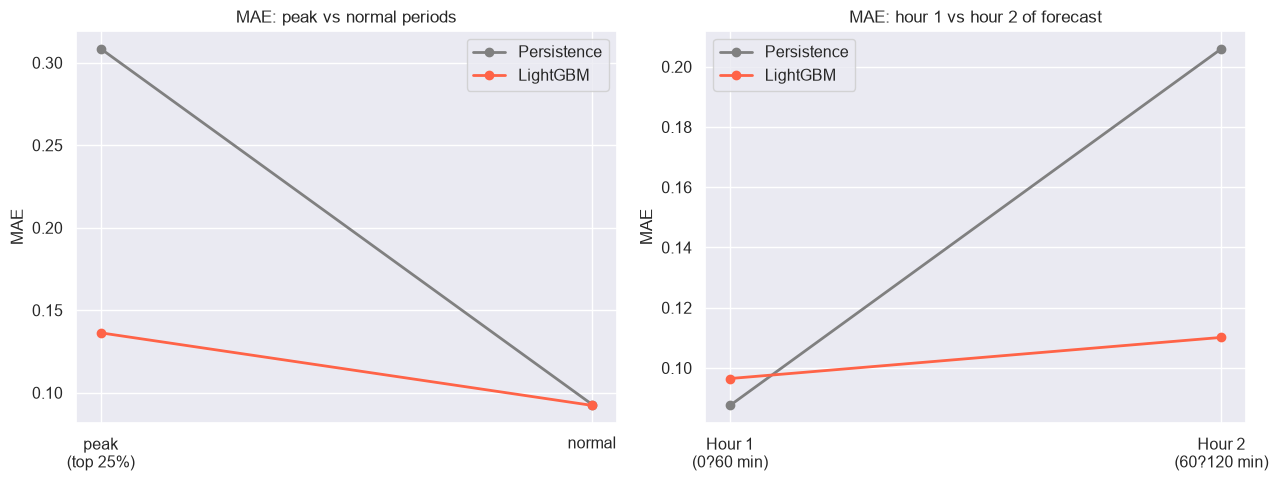

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Peak vs normal MAE comparison
ax = axes[0]
labels = ["peak\n(top 25%)", "normal"]
for model, color, label in [("ae_persist", "gray", "Persistence"), ("ae_lgbm", "tomato", "LightGBM")]:
    maes = [err.loc[err["is_peak"], model].mean(), err.loc[~err["is_peak"], model].mean()]
    ax.plot(labels, maes, marker="o", color=color, label=label, lw=2)
ax.set_title("MAE: peak vs normal periods")
ax.set_ylabel("MAE")
ax.legend()

# Hour 1 vs Hour 2 MAE comparison
ax2 = axes[1]
hour_labels = ["Hour 1\n(0?60 min)", "Hour 2\n(60?120 min)"]
for model, color, label in [("ae_persist", "gray", "Persistence"), ("ae_lgbm", "tomato", "LightGBM")]:
    maes = [
        err.loc[err["forecast_hour"] == "Hour 1 (0?60 min)",  model].mean(),
        err.loc[err["forecast_hour"] == "Hour 2 (60?120 min)", model].mean(),
    ]
    ax2.plot(hour_labels, maes, marker="o", color=color, label=label, lw=2)
ax2.set_title("MAE: hour 1 vs hour 2 of forecast")
ax2.set_ylabel("MAE")
ax2.legend()

plt.tight_layout()
plt.show()


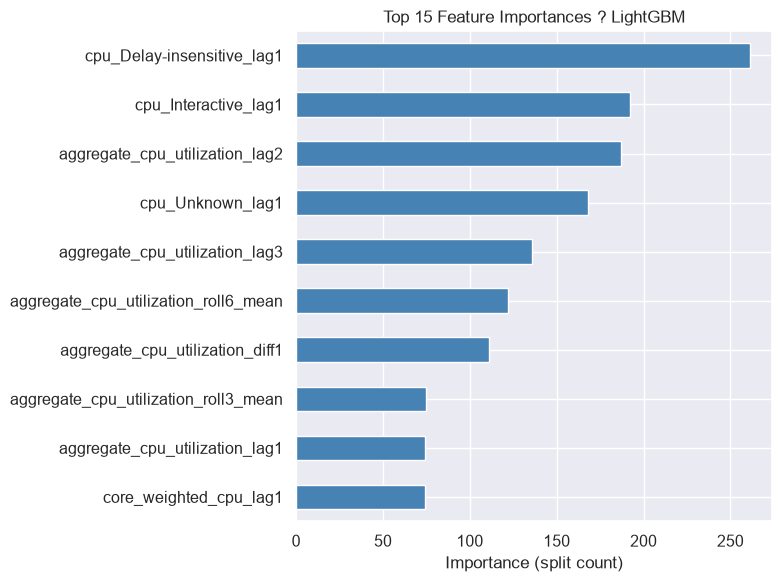

Top 10 features:
cpu_Delay-insensitive_lag1              261
cpu_Interactive_lag1                    192
aggregate_cpu_utilization_lag2          187
cpu_Unknown_lag1                        168
aggregate_cpu_utilization_lag3          136
aggregate_cpu_utilization_roll6_mean    122
aggregate_cpu_utilization_diff1         111
aggregate_cpu_utilization_roll3_mean     75
aggregate_cpu_utilization_lag1           74
core_weighted_cpu_lag1                   74


In [9]:
# Feature importance ? Best Model (LightGBM)
importances = pd.Series(
    lgbm_agg.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importances.head(15).plot.barh(ax=ax, color="steelblue")
ax.invert_yaxis()
ax.set_title("Top 15 Feature Importances ? LightGBM")
ax.set_xlabel("Importance (split count)")
plt.tight_layout()
plt.show()

print("Top 10 features:")
print(importances.head(10).to_string())


## 6. Generate `predictions.csv`


In [10]:
OUT = Path("../predictions.csv")

preds = pd.DataFrame({
    "timestamp"                : test_timestamps,
    "active_vm_count"          : 10000,           # constant — proven by EDA
    "aggregate_cpu_utilization": np.clip(final_pred, 0, 100),
})

# Validation
assert len(preds) == 24,                              "Must have 24 rows"
assert preds["timestamp"].is_monotonic_increasing,    "Timestamps not sorted"
assert preds["timestamp"].nunique() == 24,            "Duplicate timestamps"
assert (preds["active_vm_count"] >= 0).all(),         "Negative active_vm_count"
assert preds["aggregate_cpu_utilization"].between(0, 100).all(), "CPU out of [0,100]"
assert preds.isnull().sum().sum() == 0,               "NaN in predictions"

preds.to_csv(OUT, index=False)
print(f"Written: {OUT}")
print()
print(preds.to_string(index=False))

Written: ..\predictions.csv

 timestamp  active_vm_count  aggregate_cpu_utilization
     33000            10000                   9.282159
     33300            10000                   9.263663
     33600            10000                   9.228776
     33900            10000                   9.245623
     34200            10000                   9.225275
     34500            10000                   9.201968
     34800            10000                   9.274735
     35100            10000                   9.277804
     35400            10000                   9.200059
     35700            10000                   9.172283
     36000            10000                   9.256418
     36300            10000                   9.300002
     36600            10000                   9.316271
     36900            10000                   9.287826
     37200            10000                   9.318060
     37500            10000                   9.226924
     37800            10000         

In [11]:
# Final scorecard
print("=" * 55)
print("FINAL SCORECARD")
print("=" * 55)
print(f"Model            : {final_name}")
print(f"MAE              : {final_mae:.4f} %")
print(f"RMSE             : {final_rmse:.4f} %")
print(f"Baseline MAE     : {baseline_mae:.4f} % (persistence)")
print(f"nMAE             : {final_nmae:.4f}")
print(f"Improvement      : {(1-final_nmae)*100:.1f}% over persistence")
print(f"Target (nMAE<0.8): {'MET' if final_nmae < 0.8 else 'NOT MET'}")
print("=" * 55)

FINAL SCORECARD
Model            : LightGBM
MAE              : 0.1033 %
RMSE             : 0.1380 %
Baseline MAE     : 0.1468 % (persistence)
nMAE             : 0.7039
Improvement      : 29.6% over persistence
Target (nMAE<0.8): MET
